# 12 методов XAI и вердикты: что каждый метод говорит о нашей модели

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Итоговые материалы к экзамену (`docs/SD_251_UTLIMILE MATERIALE PENTRU LUCRARE_EXAMEN`: «12 методов XAI», «Почему XAI жизненно важен») требуют понимать, **на какой вопрос отвечает каждый метод**, а не просто знать 12 инструментов. В ноутбуке 08 сделаны SHAP и LIME. Здесь — остальные методы на той же модели (Random Forest, 26 признаков, тест 2024–2025) и вердикты по случаям для экзаменационных постеров.

| № | Метод | Вопрос | Где у нас |
|---|---|---|---|
| 1 | SHAP | Что внесло вклад в это решение? | ноутбук 08 + раздел 1 |
| 2 | LIME | Почему именно этот случай? | ноутбук 08 + раздел 1 |
| 3 | PDP | Каков средний эффект признака? | раздел 2 |
| 4 | ICE | Одинаков ли эффект для каждого дня? | раздел 2 |
| 5 | Feature Importance (MDI) | Какие признаки важны глобально? | раздел 3 |
| 6 | Permutation Importance | Насколько модель зависит от признака? | раздел 3 |
| 7 | Суррогатная модель | Можно ли заменить модель простыми правилами? | раздел 4 |
| 8 | Контрфакты | Что должно было быть иначе для другого решения? | раздел 5 |
| 9 | Anchors | Какие условия «закрепляют» решение? | раздел 6 |
| 10 | Grad-CAM | Куда смотрит свёрточная сеть? | только для изображений — см. ниже |
| 11 | Integrated Gradients | Какой вклад набран на пути от эталона к случаю? | раздел 7 (нейросеть MLP) |
| 12 | DeepLIFT | Чем случай отличается от эталона по активациям? | раздел 7 (нейросеть MLP) |

**Методы 10–12 созданы для нейросетей.** Integrated Gradients и DeepLIFT требуют градиентов и активаций, Grad-CAM — ещё и свёрточных карт признаков изображения. Для дерева решений их применить нельзя, поэтому IG и DeepLIFT показаны на **нейросети MLP** на тех же 26 признаках (реализованы вручную, с проверкой полноты). Grad-CAM для табличных данных не имеет смысла: у таблицы нет пространственной структуры, «куда смотрит» сеть. Он относится к лабораторной 4 (изображения).

Три опорных случая — те же, что в ноутбуке 08: **верный дождь 30.05.2024**, **ложная тревога 12.09.2024**, **пропущенный дождь 10.06.2025**.

In [1]:
import sys, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset
from features import FEATURES, FEATURE_NAMES_RU, TARGET
from xai_verdict import suggest_verdict, make_poster, VERDICTS, VERDICT_COLORS
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, r2_score
from scipy import stats

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
SEED = 42
RU = [FEATURE_NAMES_RU[f] for f in FEATURES]
N = dict(zip(FEATURES, RU))

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

data = load_dataset("chisinau")
train, valid = data[data.date.dt.year <= 2022], data[data.date.dt.year == 2023]
test = data[data.date.dt.year >= 2024].reset_index(drop=True)
X_tr, y_tr, X_te, y_te = train[FEATURES], train[TARGET].to_numpy(), test[FEATURES], test[TARGET].to_numpy()
bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf, THR = bundle["model"], bundle["threshold"]
p_te = rf.predict_proba(X_te)[:, 1]
CASES = {"Верный дождь 30.05.2024": "2024-05-30", "Ложная тревога 12.09.2024": "2024-09-12", "Пропущенный дождь 10.06.2025": "2025-06-10"}
IDX = {k: int(test.index[test.date == v][0]) for k, v in CASES.items()}
sv = np.asarray(shap.TreeExplainer(rf).shap_values(X_te)); sv = sv[..., 1] if sv.ndim == 3 else sv
detail = pd.read_csv(ROOT / "data" / "processed" / "xai_shap_lime_detail.csv", parse_dates=["Дата"])
LIME = detail.pivot(index="Дата", columns="Признак", values="LIME (норм.)")[RU].to_numpy()
pd.DataFrame({"Случай": list(CASES), "P(дождь)": [round(p_te[i], 3) for i in IDX.values()],
              "Решение": ["дождь" if p_te[i] >= THR else "сухо" for i in IDX.values()],
              "Факт": ["дождь" if y_te[i] else "сухо" for i in IDX.values()]})

,Случай,P(дождь),Решение,Факт
0,Верный дождь 30.05.2024,0.755,дождь,дождь
1,Ложная тревога 12.09.2024,0.709,дождь,сухо
2,Пропущенный дождь 10.06.2025,0.033,сухо,дождь


---
# 1. SHAP и LIME (кратко; подробно — ноутбук 08)

In [2]:
glob_shap = pd.Series(np.abs(sv).mean(0), index=RU)
glob_lime = pd.Series(np.abs(LIME).mean(0), index=RU)
corr_days = np.array([np.corrcoef(sv[i] / np.abs(sv[i]).sum(), LIME[i])[0, 1] for i in range(len(test))])
print(f"Главные по SHAP: {', '.join(glob_shap.nlargest(4).index)}")
print(f"Главные по LIME: {', '.join(glob_lime.nlargest(4).index)}")
print(f"Согласие SHAP и LIME: ρ Спирмена глобальных рейтингов = {stats.spearmanr(glob_shap, glob_lime).statistic:.2f}; "
      f"медианная корреляция по дням = {np.median(corr_days):.2f}")

Главные по SHAP: Осадки сегодня, мм, Давление, гПа, Направление ветра (sin), Часы с осадками
Главные по LIME: Осадки сегодня, мм, Давление, гПа, Направление ветра (sin), Часы с осадками
Согласие SHAP и LIME: ρ Спирмена глобальных рейтингов = 0.97; медианная корреляция по дням = 0.92


---
# 2. PDP и ICE: средний эффект и его разброс по дням

**PDP** (partial dependence): фиксируем значение признака у **всех** дней и усредняем прогноз — это средний эффект. **ICE**: то же, но кривая для **каждого** дня отдельно. Если кривые ICE параллельны, PDP честно описывает модель; если они расходятся, у признака есть **взаимодействия** с другими, и среднее их скрывает. Кривые ICE центрированы (вычтено значение в левой точке), чтобы сравнивать форму, а не уровень. Цвет — сезон.

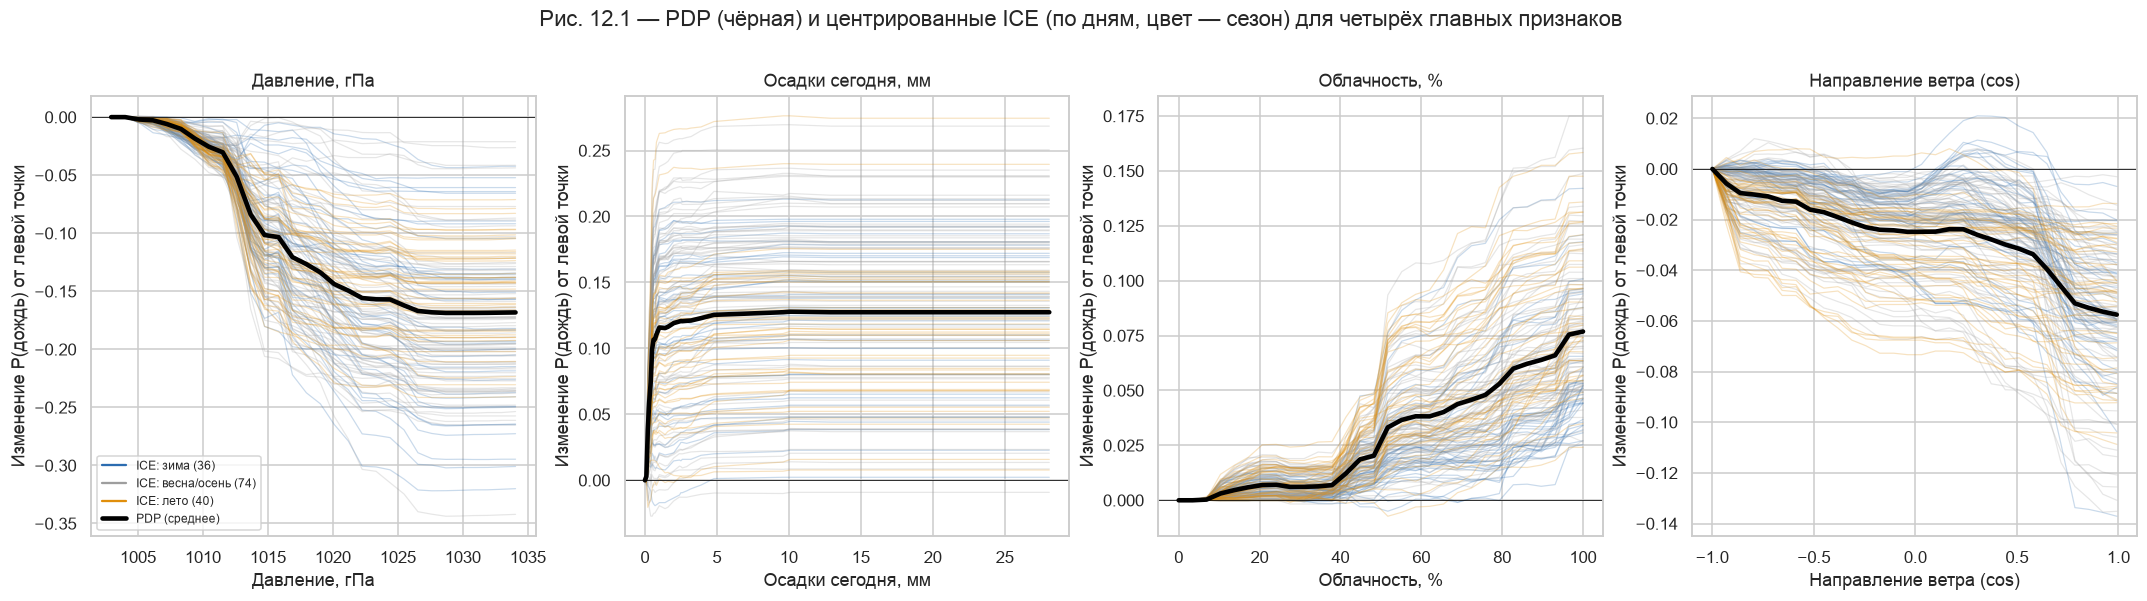

,Размах PDP,Разброс ICE в правой точке (ст. откл.),Лето: средний эффект,Зима: средний эффект
"Давление, гПа",0.169,0.061,-0.148,-0.177
"Осадки сегодня, мм",0.128,0.061,0.112,0.120
"Облачность, %",0.077,0.032,0.088,0.060
Направление ветра (cos),0.058,0.027,-0.056,-0.057


In [3]:
rng = np.random.default_rng(SEED)
sub = X_te.iloc[rng.choice(len(X_te), 150, replace=False)]
season = np.where(test.loc[sub.index, "date"].dt.month.isin([6, 7, 8]), "лето", np.where(test.loc[sub.index, "date"].dt.month.isin([12, 1, 2]), "зима", "весна/осень"))
feats_pd = ["pressure_msl_mean", "precipitation_sum", "cloud_cover_mean", "wind_dir_cos"]
fig, axes = plt.subplots(1, 4, figsize=(24, 5.2))
hetero = {}
for ax, f in zip(axes, feats_pd):
    pdr = partial_dependence(rf, sub, [f], kind="both", grid_resolution=30, percentiles=(0.02, 0.98))
    grid, ice, avg = pdr["grid_values"][0], pdr["individual"][0], pdr["average"][0]
    ice_c = ice - ice[:, [0]]
    for s, col in [("зима", "#2B6CB0"), ("весна/осень", "#9E9E9E"), ("лето", "#E08E0B")]:
        m = season == s
        ax.plot(grid, ice_c[m].T, color=col, alpha=0.25, lw=0.8)
        ax.plot([], [], color=col, label=f"ICE: {s} ({m.sum()})")
    ax.plot(grid, avg - avg[0], color="black", lw=3, label="PDP (среднее)")
    ax.axhline(0, color="black", lw=0.5)
    ax.set(xlabel=N[f], ylabel="Изменение P(дождь) от левой точки", title=N[f])
    hetero[N[f]] = {"Размах PDP": float(avg.max() - avg.min()), "Разброс ICE в правой точке (ст. откл.)": float(ice_c[:, -1].std()),
                    "Лето: средний эффект": float(ice_c[season == "лето", -1].mean()), "Зима: средний эффект": float(ice_c[season == "зима", -1].mean())}
axes[0].legend(fontsize=8)
fig.suptitle("Рис. 12.1 — PDP (чёрная) и центрированные ICE (по дням, цвет — сезон) для четырёх главных признаков", y=1.03)
save("fig_12_1_pdp_ice")
pd.DataFrame(hetero).T.round(3)

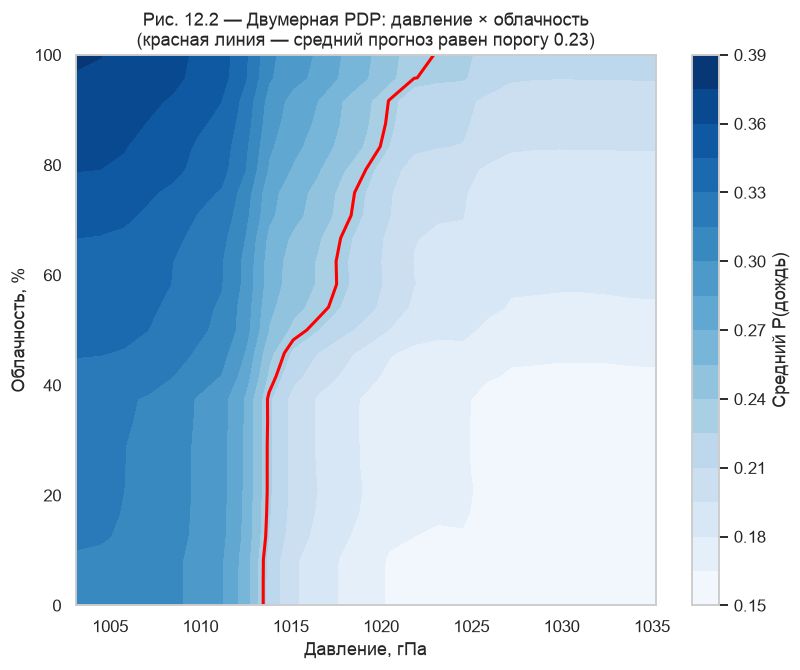

In [4]:
pd2 = partial_dependence(rf, X_te, ["pressure_msl_mean", "cloud_cover_mean"], kind="average", grid_resolution=25, percentiles=(0.02, 0.98))
fig, ax = plt.subplots(figsize=(8.5, 6.5))
cs = ax.contourf(pd2["grid_values"][0], pd2["grid_values"][1], pd2["average"][0].T, levels=15, cmap="Blues")
ax.contour(pd2["grid_values"][0], pd2["grid_values"][1], pd2["average"][0].T, levels=[THR], colors="red", linewidths=2)
plt.colorbar(cs, label="Средний P(дождь)")
ax.set(xlabel=N["pressure_msl_mean"], ylabel=N["cloud_cover_mean"],
       title="Рис. 12.2 — Двумерная PDP: давление × облачность\n(красная линия — средний прогноз равен порогу 0.23)")
save("fig_12_2_pdp_2d")

**Интерпретация (рис. 12.1–12.2).**

- **PDP показывает средние эффекты, совпадающие с физикой.**
  - **Давление** — ступенька около 1012–1015 гПа: рост давления от 1005 до 1030 гПа снижает P(дождь) в среднем на 0.17.
  - **Осадки сегодня** — почти чистая ступенька: переход от 0 к ≈ 1 мм даёт +0.12, дальше рост ничего не добавляет. Именно эту форму не может передать линейная модель (ноутбук 09).
  - **Облачность** работает только выше ≈ 40 % (+0.08 к 100 %), **направление ветра (cos)** — плавное снижение до −0.06 к ветру северных румбов.
- **ICE показывает, что среднее скрывает разброс.** Для давления и осадков сегодня кривые отдельных дней в правой точке расходятся на ±0.06 (ст. откл.), а эффект осадков у разных дней колеблется от ≈ 0 до +0.27. Значит, у этих признаков сильные **взаимодействия**: «вчерашний дождь» сильно повышает шанс дождя завтра в одних ситуациях (низкое давление, южный ветер) и почти не влияет в других. Сезон эффект меняет мало: давление летом −0.15, зимой −0.18.
- **Двумерная PDP (рис. 12.2)** показывает взаимодействие давления и облачности: средний прогноз переходит порог 0.23 только при сочетании низкого давления и большой облачности. Это «граница решений» модели в самых понятных координатах — продолжение ноутбуков 06–07.

---
# 3. Feature Importance (MDI) и Permutation Importance

**MDI** (mean decrease in impurity) — встроенная важность случайного леса: насколько признак уменьшал неоднородность при разбиениях **на обучении**. **Permutation importance** — насколько падает качество на **тесте**, если перемешать значения признака. Известный недостаток MDI — он завышает важность непрерывных признаков с множеством возможных порогов и не видит, полезен ли признак на новых данных.

ρ Спирмена между рейтингами: {'MDI – Перестановка (ΔPR-AUC)': np.float64(0.68), 'MDI – SHAP (средний |вклад|)': np.float64(0.95), 'Перестановка (ΔPR-AUC) – SHAP (средний |вклад|)': np.float64(0.66)}


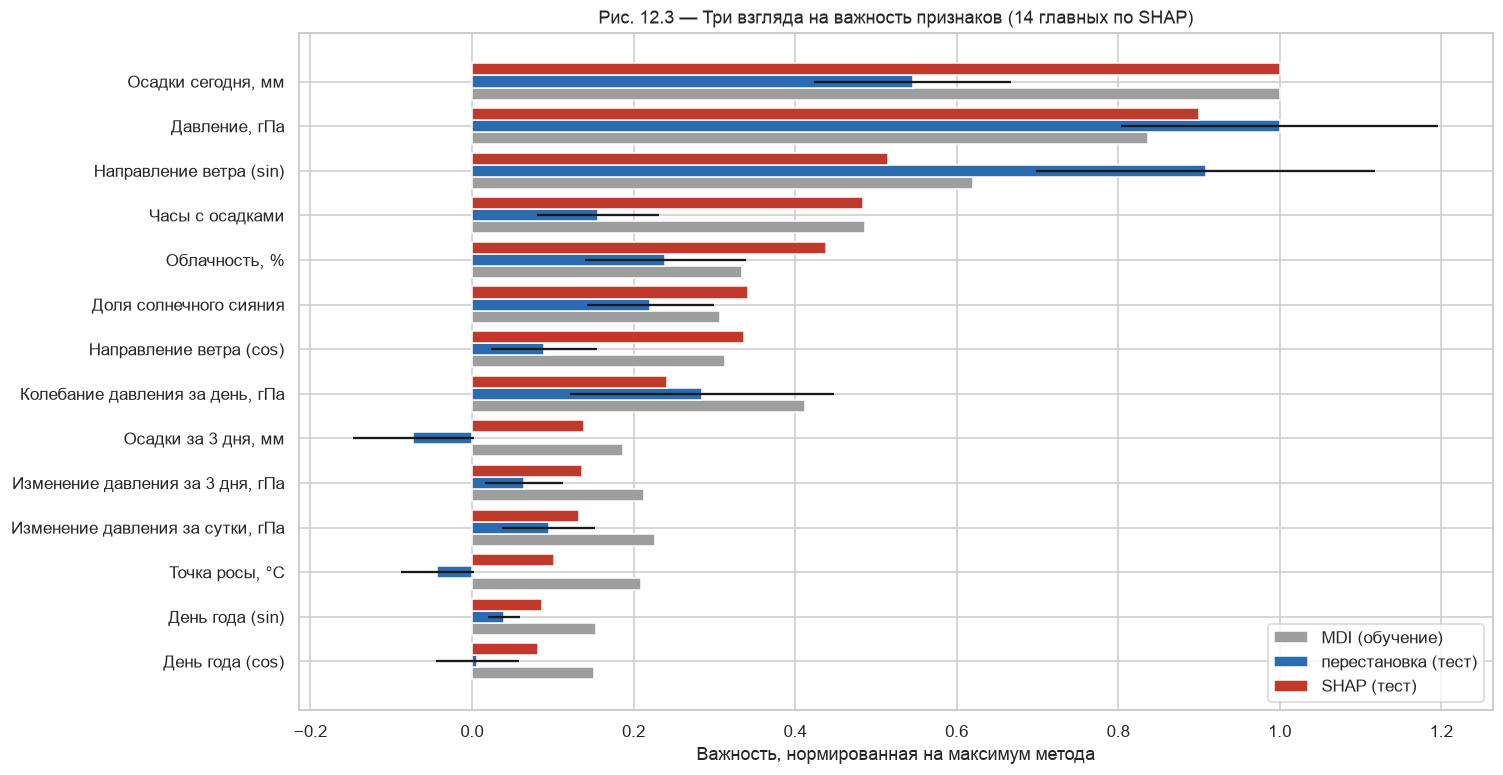

MDI завышает (MDI выше перестановки на ≥ 5 мест): Точка росы, °C, Осадки за 3 дня, мм, Скорость ветра, км/ч, Средняя температура, °C, Максимальная влажность, %
MDI занижает: Снегопад, см, Дефицит точки росы, °C, Изменение влажности за сутки, Дождливых дней за 7
Перестановка ≤ 0 (перемешивание не вредит качеству на тесте): Средняя температура, °C, Точка росы, °C, Средняя влажность, %, Максимальная влажность, %, Снегопад, см, Скорость ветра, км/ч, Дефицит упругости пара, кПа, Облачность вчера, %, Осадки за 3 дня, мм


,MDI,Перестановка (ΔPR-AUC),SHAP (средний |вклад|)
"Осадки сегодня, мм",0.1473,0.0402,0.0546
"Давление, гПа",0.1232,0.0738,0.0491
Направление ветра (sin),0.0915,0.0670,0.0281
Часы с осадками,0.0717,0.0115,0.0264
"Облачность, %",0.0493,0.0177,0.0239
Доля солнечного сияния,0.0452,0.0163,0.0186
Направление ветра (cos),0.0462,0.0066,0.0184
"Колебание давления за день, гПа",0.0608,0.0210,0.0132
"Осадки за 3 дня, мм",0.0276,-0.0053,0.0076
"Изменение давления за 3 дня, гПа",0.0313,0.0047,0.0075


In [5]:
mdi = pd.Series(rf.feature_importances_, index=RU)
pi = permutation_importance(rf, X_te, y_te, scoring="average_precision", n_repeats=15, random_state=SEED, n_jobs=-1)
pim = pd.Series(pi.importances_mean, index=RU); pis = pd.Series(pi.importances_std, index=RU)
imp = pd.DataFrame({"MDI": mdi, "Перестановка (ΔPR-AUC)": pim, "SHAP (средний |вклад|)": glob_shap})
ranks = imp.rank(ascending=False)
print("ρ Спирмена между рейтингами:", {f"{a} – {b}": round(stats.spearmanr(imp[a], imp[b]).statistic, 2)
                                      for a, b in itertools.combinations(imp.columns, 2)})
fig, ax = plt.subplots(figsize=(14, 8))
o = imp["SHAP (средний |вклад|)"].sort_values().index[-14:]
norm = imp.loc[o] / imp.loc[o].max()
y = np.arange(len(o))
ax.barh(y - 0.27, norm["MDI"], 0.27, color="#9E9E9E", label="MDI (обучение)")
ax.barh(y, norm["Перестановка (ΔPR-AUC)"], 0.27, color="#2B6CB0", label="перестановка (тест)", xerr=(pis[o] / imp.loc[o, "Перестановка (ΔPR-AUC)"].max()).values)
ax.barh(y + 0.27, norm["SHAP (средний |вклад|)"], 0.27, color="#C0392B", label="SHAP (тест)")
ax.set_yticks(y); ax.set_yticklabels(o)
ax.set(xlabel="Важность, нормированная на максимум метода", title="Рис. 12.3 — Три взгляда на важность признаков (14 главных по SHAP)")
ax.legend()
save("fig_12_3_importances")
diff_rank = (ranks["MDI"] - ranks["Перестановка (ΔPR-AUC)"]).sort_values()
print("MDI завышает (MDI выше перестановки на ≥ 5 мест):", ", ".join(diff_rank[diff_rank <= -5].index))
print("MDI занижает:", ", ".join(diff_rank[diff_rank >= 5].index))
print("Перестановка ≤ 0 (перемешивание не вредит качеству на тесте):", ", ".join(pim[pim <= 0].index))
imp.sort_values("SHAP (средний |вклад|)", ascending=False).head(10).round(4)

**Интерпретация (рис. 12.3).**

- **Три метода согласны в главном:** первые три признака — осадки сегодня, давление, направление ветра (sin) — у всех. Рейтинги MDI и SHAP почти совпадают (ρ = 0.95): оба описывают, как модель **использует** признак.
- **Пермутационная важность отвечает на другой вопрос** — нужен ли признак для качества на **новых** данных. Её согласие с MDI и SHAP заметно слабее (ρ = 0.68 и 0.66).
  - У 9 признаков она **≤ 0**: перемешивание не портит качество на тесте. Это средняя температура, точка росы, средняя и максимальная влажность, снегопад, скорость ветра, дефицит упругости пара, облачность вчера, осадки за 3 дня.
  - Модель ими пользуется (MDI > 0), но информация в них **дублируется** другими признаками (влажность ↔ облачность и точка росы; осадки за 3 дня ↔ осадки сегодня).
- **Классический перекос MDI подтвердился:** MDI завышает непрерывные признаки с множеством порогов — точку росы, осадки за 3 дня, скорость ветра, температуру — и занижает редкие (снегопад) и дискретные (дождливых дней за 7).
- **Вывод (сделали X, потому что Y):** для отчёта о важности используем SHAP и перестановку, а не встроенный MDI, — MDI считается на обучении и не видит дублирования. Признаки с нулевой пермутационной важностью — кандидаты на удаление при упрощении модели (связь с L1-отбором в ноутбуке 09).

---
# 4. Суррогатная модель: можно ли заменить лес простыми правилами?

Обучаем **неглубокое дерево** предсказывать не факт, а **вероятность Random Forest** (то есть имитировать модель). Мера качества суррогата — **верность** (fidelity): R² по вероятностям и доля совпадающих решений при пороге 0.23 на тесте. Чем глубже дерево, тем оно вернее, но тем хуже читается.

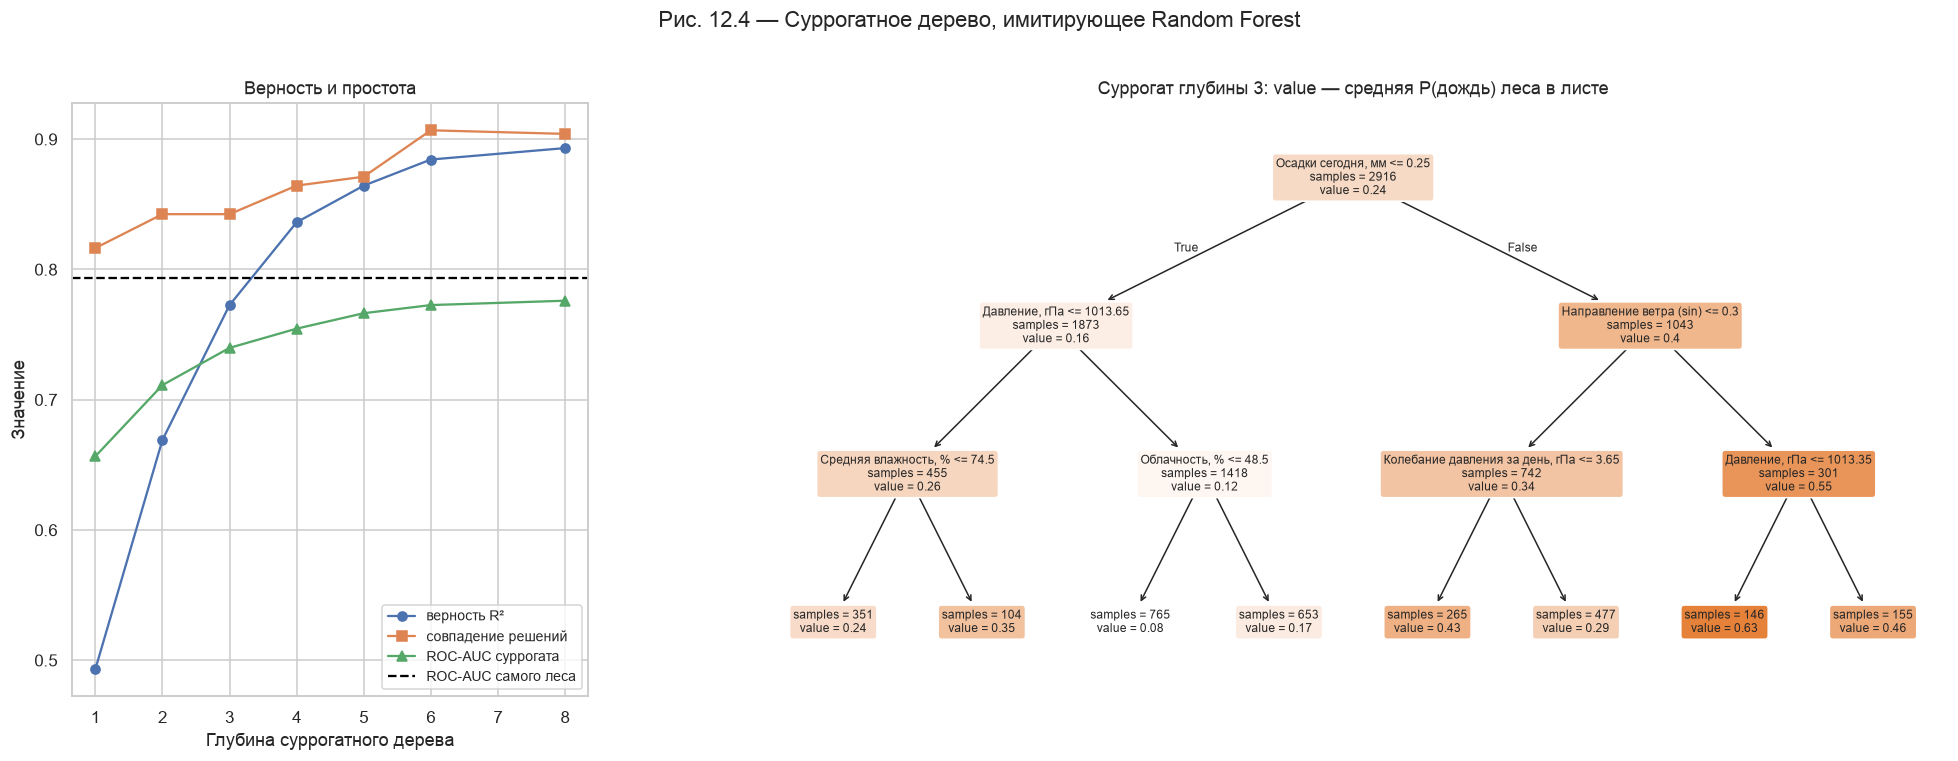

|--- Осадки сегодня, мм <= 0.3
|   |--- Давление, гПа <= 1013.6
|   |   |--- Средняя влажность, % <= 74.5
|   |   |   |--- value: [0.2]
|   |   |--- Средняя влажность, % >  74.5
|   |   |   |--- value: [0.4]
|   |--- Давление, гПа >  1013.6
|   |   |--- Облачность, % <= 48.5
|   |   |   |--- value: [0.1]
|   |   |--- Облачность, % >  48.5
|   |   |   |--- value: [0.2]
|--- Осадки сегодня, мм >  0.3
|   |--- Направление ветра (sin) <= 0.3
|   |   |--- Колебание давления за день, гПа <= 3.6
|   |   |   |--- value: [0.4]
|   |   |--- Колебание давления за день, гПа >  3.6
|   |   |   |--- value: [0.3]
|   |--- Направление ветра (sin) >  0.3
|   |   |--- Давление, гПа <= 1013.4
|   |   |   |--- value: [0.6]
|   |   |--- Давление, гПа >  1013.4
|   |   |   |--- value: [0.5]



,Глубина,Листьев,Верность R² (тест),Совпадение решений,ROC-AUC суррогата по факту,F1 суррогата
0,1,2,0.493,0.816,0.657,0.460
1,2,4,0.669,0.842,0.711,0.474
2,3,8,0.773,0.842,0.740,0.474
3,4,16,0.836,0.864,0.755,0.484
4,5,27,0.864,0.871,0.766,0.493
5,6,45,0.884,0.907,0.773,0.522
6,8,67,0.893,0.904,0.776,0.504


In [6]:
p_tr = rf.predict_proba(X_tr)[:, 1]
rows, trees = [], {}
for depth in [1, 2, 3, 4, 5, 6, 8]:
    t = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=30, random_state=SEED).fit(X_tr, p_tr)
    q = t.predict(X_te); trees[depth] = t
    rows.append({"Глубина": depth, "Листьев": t.get_n_leaves(), "Верность R² (тест)": r2_score(p_te, q),
                 "Совпадение решений": ((q >= THR) == (p_te >= THR)).mean(), "ROC-AUC суррогата по факту": roc_auc_score(y_te, q),
                 "F1 суррогата": f1_score(y_te, q >= THR)})
sur = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 2.3]})
axes[0].plot(sur["Глубина"], sur["Верность R² (тест)"], "o-", label="верность R²")
axes[0].plot(sur["Глубина"], sur["Совпадение решений"], "s-", label="совпадение решений")
axes[0].plot(sur["Глубина"], sur["ROC-AUC суррогата по факту"], "^-", label="ROC-AUC суррогата")
axes[0].axhline(roc_auc_score(y_te, p_te), color="black", ls="--", label="ROC-AUC самого леса")
axes[0].set(xlabel="Глубина суррогатного дерева", ylabel="Значение", title="Верность и простота"); axes[0].legend(fontsize=9)
plot_tree(trees[3], feature_names=RU, filled=True, rounded=True, impurity=False, precision=2, fontsize=8, ax=axes[1])
axes[1].set_title("Суррогат глубины 3: value — средняя P(дождь) леса в листе")
fig.suptitle("Рис. 12.4 — Суррогатное дерево, имитирующее Random Forest", y=1.0)
save("fig_12_4_surrogate")
print(export_text(trees[3], feature_names=RU, decimals=1))
sur.round(3)

**Интерпретация (рис. 12.4).**

- **Компромисс «простота ↔ верность».**
  - Дерево глубины 3 (8 правил) объясняет **77 %** дисперсии вероятностей леса и совпадает с его решением в **84 %** дней.
  - Глубины 6 (45 листьев) хватает для R² = 0.88 и 91 % совпадений; ROC-AUC суррогата растёт до 0.773 — почти как у самого леса (0.793).
- **Правила дерева глубины 3 читаются как синоптическое правило:**
  1. корень — **были ли осадки сегодня (> 0.3 мм)**;
  2. без осадков решают давление (≤ 1013.6 гПа) и влажность (> 74.5 %);
  3. с осадками — **ветер восточной составляющей** (sin > 0.3) и давление ≤ 1013.4 гПа: средняя P(дождь) в этом листе 0.6, самая высокая.
- **Чего суррогат не умеет.** На 16 % дней его решение расходится с лесом, это как раз неуверенные дни у порога. Поэтому суррогат годится для **объяснения логики** модели (пользователю, на защите), но не для замены модели: на тесте он теряет 0.05 ROC-AUC при глубине 3.

---
# 5. Контрфакты: что должно было быть иначе?

Для каждого опорного случая ищем **минимальное изменение**, которое переводит прогноз через порог 0.23. Перебираем один признак (в пределах 1–99 % значений обучения) и пары признаков. Расстояние меряется в стандартных отклонениях. **Правдоподобие** проверяем расстоянием до ближайшего реального дня обучения (в стандартизованном пространстве): контрфакт, не похожий ни на один реальный день, — математический артефакт.

Важно: погоду нельзя «изменить», поэтому контрфакт здесь — не совет, а вопрос **«насколько близко было другое решение?»**.

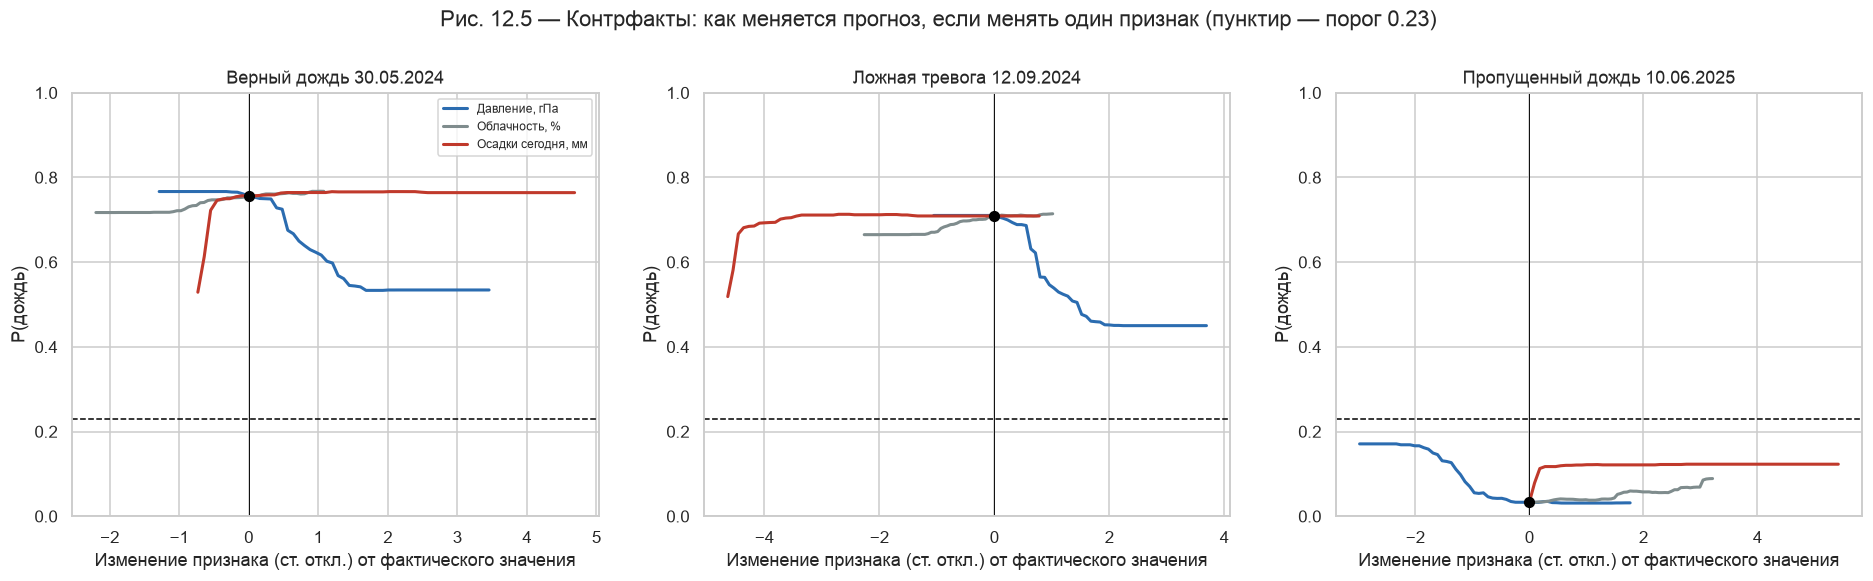

,Случай,P было,Изменение,P стало,Расстояние (ст. откл.),До ближайшего реального дня,Обычно (типичный день теста)
0,Верный дождь 30.05.2024,0.755,"4 признака(ов): Осадки сегодня, мм: 2.6 → 0.0;...",0.176,6.82,3.38,2.47
1,Ложная тревога 12.09.2024,0.709,"4 признака(ов): Давление, гПа: 1007.4 → 1024.6...",0.184,11.82,2.46,2.47
2,Пропущенный дождь 10.06.2025,0.033,"Давление, гПа: 1022.2 → 1011.5; Осадки сегодня...",0.241,1.62,2.42,2.47
3,Пропущенный дождь 10.06.2025,0.033,"Давление, гПа: 1022.2 → 1003.9; Направление ве...",0.231,5.05,3.04,2.47


In [7]:
sc = StandardScaler().fit(X_tr)
Z_tr = sc.transform(X_tr)
lo, hi = X_tr.quantile(0.01), X_tr.quantile(0.99)
std = X_tr.std()
def nearest_real(x):
    return float(np.min(np.linalg.norm(Z_tr - sc.transform(pd.DataFrame([x], columns=FEATURES)), axis=1)))
typical = np.median([nearest_real(X_te.iloc[i]) for i in range(0, len(X_te), 15)])
cf_rows, cf_curves = [], {}
CF_FEATS = ["pressure_msl_mean", "precipitation_sum", "cloud_cover_mean", "precipitation_hours", "wind_dir_cos", "wind_dir_sin",
            "pressure_intraday_range", "relative_humidity_2m_mean", "dew_point_depression", "pressure_change_1d"]
for case, i in IDX.items():
    x = X_te.iloc[i].copy(); p0 = p_te[i]; target = p0 < THR       # we want to cross the threshold
    best = []
    for f in CF_FEATS:
        grid = np.linspace(lo[f], hi[f], 60)
        Xg = pd.DataFrame(np.repeat(x.to_numpy()[None], len(grid), 0), columns=FEATURES); Xg[f] = grid
        pg = rf.predict_proba(Xg)[:, 1]
        cf_curves[(case, f)] = (grid, pg)
        ok = (pg >= THR) if target else (pg < THR)
        if ok.any():
            j = np.argmin(np.where(ok, np.abs(grid - x[f]), np.inf))
            best.append((abs(grid[j] - x[f]) / std[f], f"{N[f]}: {x[f]:.1f} → {grid[j]:.1f}", pg[j], {f: grid[j]}))
    for f1, f2 in itertools.combinations(["pressure_msl_mean", "cloud_cover_mean", "precipitation_sum", "wind_dir_cos", "precipitation_hours"], 2):
        g1, g2 = np.linspace(lo[f1], hi[f1], 25), np.linspace(lo[f2], hi[f2], 25)
        G = np.array(list(itertools.product(g1, g2)))
        Xg = pd.DataFrame(np.repeat(x.to_numpy()[None], len(G), 0), columns=FEATURES); Xg[f1], Xg[f2] = G[:, 0], G[:, 1]
        pg = rf.predict_proba(Xg)[:, 1]
        ok = (pg >= THR) if target else (pg < THR)
        if ok.any():
            dist = np.abs(G[:, 0] - x[f1]) / std[f1] + np.abs(G[:, 1] - x[f2]) / std[f2]
            j = np.argmin(np.where(ok, dist, np.inf))
            best.append((dist[j], f"{N[f1]}: {x[f1]:.1f} → {G[j, 0]:.1f}; {N[f2]}: {x[f2]:.1f} → {G[j, 1]:.1f}", pg[j], {f1: G[j, 0], f2: G[j, 1]}))
    if not best:   # neither one nor two features suffice: greedy search over several features
        xc, changed, text = x.copy(), {}, []
        for _ in range(6):
            cand = []
            for f in CF_FEATS:
                if f in changed: continue
                grid = np.linspace(lo[f], hi[f], 40)
                Xg = pd.DataFrame(np.repeat(xc.to_numpy()[None], len(grid), 0), columns=FEATURES); Xg[f] = grid
                pg = rf.predict_proba(Xg)[:, 1]
                j = int(np.argmax(pg) if target else np.argmin(pg))
                cand.append((pg[j], f, grid[j]))
            pbest, f, v = max(cand) if target else min(cand)
            changed[f] = v; text.append(f"{N[f]}: {x[f]:.1f} → {v:.1f}"); xc[f] = v
            if (pbest >= THR) == target: break
        d = sum(abs(changed[f] - x[f]) / std[f] for f in changed)
        best.append((d, f"{len(changed)} признака(ов): " + "; ".join(text), pbest, changed))
    for d, text, pnew, change in sorted(best, key=lambda t: t[0])[:3]:
        xc = x.copy()
        for f, v in change.items(): xc[f] = v
        cf_rows.append({"Случай": case, "P было": round(p0, 3), "Изменение": text, "P стало": round(pnew, 3),
                        "Расстояние (ст. откл.)": round(d, 2), "До ближайшего реального дня": round(nearest_real(xc), 2),
                        "Обычно (типичный день теста)": round(typical, 2)})
cf = pd.DataFrame(cf_rows)
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, (case, i) in zip(axes, IDX.items()):
    for f, col in [("pressure_msl_mean", "#2B6CB0"), ("cloud_cover_mean", "#7F8C8D"), ("precipitation_sum", "#C0392B")]:
        grid, pg = cf_curves[(case, f)]
        ax.plot((grid - X_te.iloc[i][f]) / std[f], pg, color=col, lw=2, label=N[f])
    ax.axhline(THR, color="black", ls="--", lw=1); ax.axvline(0, color="black", lw=0.6)
    ax.scatter([0], [p_te[i]], color="black", zorder=3, s=40)
    ax.set(xlabel="Изменение признака (ст. откл.) от фактического значения", ylabel="P(дождь)", title=case, ylim=(0, 1))
axes[0].legend(fontsize=8)
fig.suptitle("Рис. 12.5 — Контрфакты: как меняется прогноз, если менять один признак (пунктир — порог 0.23)", y=1.03)
save("fig_12_5_counterfactuals")
cf

**Интерпретация (рис. 12.5).**

- **Пропущенный дождь 10.06.2025 «был близко»:** достаточно, чтобы давление было 1011.5 гПа вместо 1022.2 и сегодня выпало 0.8 мм (расстояние 1.6 ст. откл.). Такой день правдоподобен: до ближайшего реального дня обучения 2.42 — столько же, сколько у типичного дня теста (2.47). Модель не «ошиблась логикой»: при высоком давлении и сухом дне конвективная гроза по суточным данным не видна (тот же вывод, что в ноутбуке 08).
- **Верный дождь 30.05.2024 и ложная тревога 12.09.2024 — решения очень устойчивые:** ни один признак и ни одна пара не переводят их через порог. Понадобилось изменить **4 признака одновременно** — убрать сегодняшние осадки (2.6 и 16.5 мм → 0), поднять давление до 1024–1028 гПа, развернуть ветер и обнулить часы с осадками (расстояние 6.8 и 11.8 ст. откл.).
- **Главный вывод по ложной тревоге:** 12.09.2024 с точки зрения модели был «образцовым» дождливым днём — ливень 16.5 мм, давление 1007 гПа, восточный ветер. Чтобы получить «сухо», пришлось бы описать совсем другой день. Это та же картина, что дал SHAP в ноутбуке 08 («ошибка от нехватки данных, а не логики»), но с другой стороны: **ни одно правдоподобное малое изменение не исправило бы прогноз**.
- **Ограничение метода:** контрфакт меняет признаки независимо, а в атмосфере они связаны (давление, облачность и осадки меняются вместе). Поэтому контрфакт отвечает на вопрос «насколько близко было другое решение», а не «что сделать», — погоду изменить нельзя.

---
# 6. Anchors: какие условия «закрепляют» решение?

**Anchor** — правило «ЕСЛИ условия, ТО решение», при котором модель почти всегда (точность ≥ 0.9) принимает то же решение, что и для разбираемого дня. Чем больше дней покрывает правило (**покрытие**), тем оно общее. Библиотеки `alibi`/`anchor-exp` в окружении нет, поэтому алгоритм реализован прямо по идее метода: признаки разбиваются на квартили (как в LIME), условие «признак в том же квартиле, что у дня» добавляется жадно (лучевой поиск, ширина 5), пока точность не достигнет 0.9. Точность и покрытие считаются на **реальных** днях 2015–2023 по решениям модели.

In [8]:
pool = pd.concat([X_tr, valid[FEATURES]]); pred_pool = rf.predict_proba(pool)[:, 1] >= THR
edges = {f: np.unique(np.quantile(pool[f], [0, 0.25, 0.5, 0.75, 1])) for f in FEATURES}
def bin_of(f, v):
    e = edges[f]; k = int(np.clip(np.searchsorted(e, v, side="right") - 1, 0, len(e) - 2)); return e[k], e[k + 1]
def rule_mask(rule):
    m = np.ones(len(pool), bool)
    for f, (a, b) in rule: m &= (pool[f] >= a).to_numpy() & (pool[f] <= b).to_numpy()
    return m
anc_rows = []
for case, i in IDX.items():
    x, decision = X_te.iloc[i], p_te[i] >= THR
    cands = [(f, bin_of(f, x[f])) for f in FEATURES]
    beam, found = [[]], None
    for size in range(1, 6):
        scored = []
        for rule in beam:
            for c in cands:
                if any(c[0] == r[0] for r in rule): continue
                r2 = rule + [c]; m = rule_mask(r2)
                if m.sum() < 15: continue
                scored.append((float((pred_pool[m] == decision).mean()), float(m.mean()), r2))
        scored.sort(key=lambda t: (t[0], t[1]), reverse=True)
        ok = [s for s in scored if s[0] >= 0.9]
        if ok:
            found = max(ok, key=lambda t: t[1]); break
        beam = [s[2] for s in scored[:5]]
    prec, cov, rule = found if found else scored[0]
    text = " И ".join(f"{N[f]} ∈ [{a:.1f}; {b:.1f}]" for f, (a, b) in rule)
    anc_rows.append({"Случай": case, "Решение модели": "дождь" if decision else "сухо", "Anchor (ЕСЛИ …)": text,
                     "Точность": round(prec, 3), "Покрытие": f"{cov:.1%}", "Дней 2015–2023 под правилом": int(rule_mask(rule).sum())})
anchors = pd.DataFrame(anc_rows)
anchors

,Случай,Решение модели,Anchor (ЕСЛИ …),Точность,Покрытие,Дней 2015–2023 под правилом
0,Верный дождь 30.05.2024,дождь,"Осадки сегодня, мм ∈ [0.9; 35.9] И Осадки за 3...",0.929,15.4%,505
1,Ложная тревога 12.09.2024,дождь,"Осадки сегодня, мм ∈ [0.9; 35.9] И Осадки за 3...",0.929,15.4%,505
2,Пропущенный дождь 10.06.2025,сухо,"Давление, гПа ∈ [1021.6; 1043.0] И Часы с осад...",0.903,23.0%,756


**Интерпретация (Anchors).**

- **Дождливые дни** (30.05.2024 и ложная тревога 12.09.2024) закреплены одним и тем же правилом: **«ЕСЛИ осадки сегодня ≥ 0.9 мм И осадки за 3 дня ≥ 5.3 мм, ТО дождь»**. Точность 0.93: модель так решает в 93 % из 505 подходящих дней 2015–2023, покрытие 15 %. Для модели оба дня — один и тот же тип ситуации, «продолжающийся дождливый период», поэтому ложная тревога объяснима: правило верно в большинстве похожих дней, но не всегда.
- **Пропущенный дождь 10.06.2025** закреплён правилом **«ЕСЛИ давление ≥ 1021.6 гПа И часов с осадками ≤ 4, ТО сухо»** (точность 0.90, покрытие 23 %, 756 дней). Это самое типичное «сухое» правило, и гроза в такой день — редкое исключение.
- **Чем Anchors отличаются от SHAP и LIME:** они не делят вклад, а дают **достаточное условие** решения на понятном языке и с измеримой надёжностью (точность и покрытие на реальных днях). Для тревог это самая удобная форма объяснения: «тревога, потому что второй день подряд идёт дождь».

---
# 7. Integrated Gradients и DeepLIFT на нейросети (методы 11–12)

Обучаем **MLP** (ReLU, стандартизованные признаки, без `early_stopping` — см. грабли в ноутбуке 06; число слоёв и L2-штраф alpha выбираются по валидации 2023) на тех же данных и объясняем её **логит** (log-odds дождя):

- **Integrated Gradients**: вклад признака = (x − x′) × средний градиент на прямом пути от эталона x′ к дню x (64 шага; градиенты — численно). Эталон x′ — средний день обучения (нули после стандартизации).
- **DeepLIFT** (правило Rescale): активации каждого нейрона сравниваются с их значениями на эталоне, и разница логита распределяется по входам через «множители» Δвыход/Δвход — реализовано прямо по весам сети.

Оба метода обладают свойством **полноты**: сумма вкладов равна logit(x) − logit(x′). Проверяем это и сравниваем с SHAP той же сети.

Слои   (16,)  (32, 16)
alpha                 
0.01   0.727     0.700
0.10   0.727     0.689
1.00   0.748     0.744
3.00   0.737     0.743
10.00  0.728     0.727
Выбрано по валидации: слои (16,), alpha 1.0. MLP: ROC-AUC тест 0.763, PR-AUC 0.516 (Random Forest: 0.793 / 0.551)


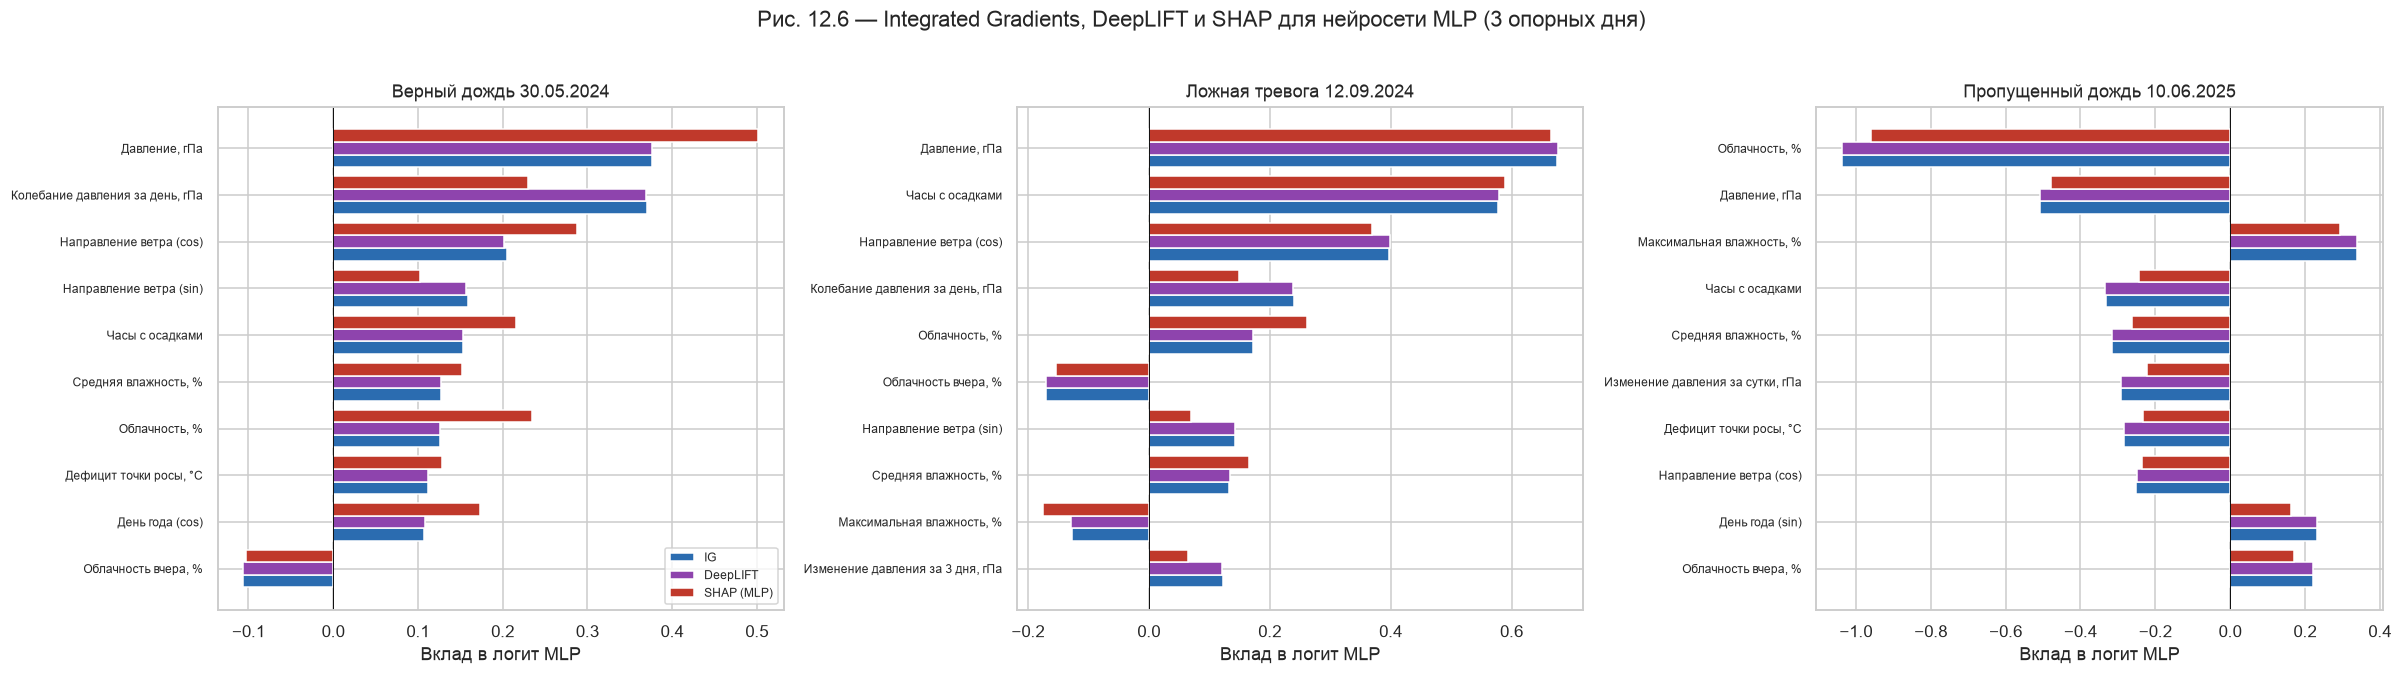

,Случай,P (MLP),logit(x) − logit(эталон),Σ IG,Σ DeepLIFT,"r(IG, DeepLIFT)","r(IG, SHAP)",Главный по IG,Главный по SHAP RF
0,Верный дождь 30.05.2024,0.729,1.972,1.973,1.972,1.0,0.855,"Давление, гПа","Осадки сегодня, мм"
1,Ложная тревога 12.09.2024,0.776,2.225,2.218,2.225,1.0,0.916,"Давление, гПа","Осадки сегодня, мм"
2,Пропущенный дождь 10.06.2025,0.051,-1.932,-1.932,-1.932,1.0,0.981,"Облачность, %","Давление, гПа"


In [9]:
# architecture and L2 penalty chosen on the validation year 2023 (an under-regularized net overfits: ROC-AUC 0.66)
grid_rows = []
for hl in [(32, 16), (16,)]:
    for a in [0.01, 0.1, 1.0, 3.0, 10.0]:
        m = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hl, alpha=a, max_iter=600, random_state=SEED)).fit(X_tr, y_tr)
        grid_rows.append({"Слои": str(hl), "alpha": a, "ROC-AUC валидация": roc_auc_score(valid[TARGET], m.predict_proba(valid[FEATURES])[:, 1]), "model": m})
g = pd.DataFrame(grid_rows); best = g.loc[g["ROC-AUC валидация"].idxmax()]
mlp = best["model"]
p_mlp = mlp.predict_proba(X_te)[:, 1]
print(g.drop(columns="model").pivot(index="alpha", columns="Слои", values="ROC-AUC валидация").round(3).to_string())
print(f"Выбрано по валидации: слои {best['Слои']}, alpha {best['alpha']}. MLP: ROC-AUC тест {roc_auc_score(y_te, p_mlp):.3f}, "
      f"PR-AUC {average_precision_score(y_te, p_mlp):.3f} (Random Forest: {roc_auc_score(y_te, p_te):.3f} / {average_precision_score(y_te, p_te):.3f})")
scaler, net = mlp[0], mlp[-1]
W, B = net.coefs_, net.intercepts_
def forward(z):                      # z: standardized inputs (n, 26) → list of pre-activations and the output logit
    a, pre = z, []
    for k, (w, b) in enumerate(zip(W, B)):
        h = a @ w + b; pre.append(h)
        a = np.maximum(h, 0) if k < len(W) - 1 else h
    return pre, a[:, 0]
def logit(z): return forward(np.atleast_2d(z))[1]
z_base = np.zeros((1, len(FEATURES)))
def integrated_gradients(z, steps=64, eps=1e-4):
    alphas = (np.arange(steps) + 0.5) / steps
    path = z_base + alphas[:, None] * (z - z_base)
    grads = np.zeros_like(path)
    for j in range(path.shape[1]):
        e = np.zeros(path.shape[1]); e[j] = eps
        grads[:, j] = (logit(path + e) - logit(path - e)) / (2 * eps)
    return (z - z_base)[0] * grads.mean(0)
def deeplift(z):
    pre_x, _ = forward(z); pre_r, _ = forward(z_base)
    m = np.ones((1, 1))                                       # multiplier of the output logit
    for k in range(len(W) - 1, -1, -1):
        m = m @ W[k].T                                        # to the activations of layer k-1 (or to the inputs)
        if k > 0:                                             # rescale rule for the ReLU of layer k-1
            dz = pre_x[k - 1] - pre_r[k - 1]
            dh = np.maximum(pre_x[k - 1], 0) - np.maximum(pre_r[k - 1], 0)
            mult = np.where(np.abs(dz) > 1e-9, dh / np.where(np.abs(dz) > 1e-9, dz, 1), (pre_x[k - 1] > 0).astype(float))
            m = m * mult
    return (z - z_base)[0] * m[0]
mlp_logit = lambda A: logit(scaler.transform(pd.DataFrame(A, columns=FEATURES)))
bg = shap.sample(X_tr, 200, random_state=SEED)
ex_mlp = shap.Explainer(mlp_logit, shap.maskers.Independent(bg, max_samples=200), algorithm="permutation")
rows, attr = [], {}
for case, i in IDX.items():
    z = scaler.transform(X_te.iloc[[i]])
    ig, dl = integrated_gradients(z), deeplift(z)
    sh = ex_mlp(X_te.iloc[[i]], max_evals=2000).values[0]
    delta = float(logit(z)[0] - logit(z_base)[0])
    attr[case] = pd.DataFrame({"IG": ig, "DeepLIFT": dl, "SHAP (MLP)": sh}, index=RU)
    rows.append({"Случай": case, "P (MLP)": round(float(p_mlp[i]), 3), "logit(x) − logit(эталон)": round(delta, 3),
                 "Σ IG": round(ig.sum(), 3), "Σ DeepLIFT": round(dl.sum(), 3),
                 "r(IG, DeepLIFT)": round(np.corrcoef(ig, dl)[0, 1], 3), "r(IG, SHAP)": round(np.corrcoef(ig, sh)[0, 1], 3),
                 "Главный по IG": RU[int(np.argmax(np.abs(ig)))], "Главный по SHAP RF": RU[int(np.argmax(np.abs(sv[i])))]})
neural = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=False)
for ax, (case, a) in zip(axes, attr.items()):
    top = a["IG"].abs().sort_values().index[-10:]
    yy = np.arange(len(top))
    for k, (col, c) in enumerate([("IG", "#2B6CB0"), ("DeepLIFT", "#8E44AD"), ("SHAP (MLP)", "#C0392B")]):
        ax.barh(yy + (k - 1) * 0.27, a.loc[top, col], 0.27, color=c, label=col)
    ax.set_yticks(yy); ax.set_yticklabels(top, fontsize=8); ax.axvline(0, color="black", lw=0.6)
    ax.set(title=case, xlabel="Вклад в логит MLP")
axes[0].legend(fontsize=8)
fig.suptitle("Рис. 12.6 — Integrated Gradients, DeepLIFT и SHAP для нейросети MLP (3 опорных дня)", y=1.02)
plt.tight_layout(); save("fig_12_6_ig_deeplift")
neural

**Интерпретация (методы 11–12).**

- **Нейросеть сначала переобучилась.** С двумя слоями и слабым штрафом (alpha = 0.01) ROC-AUC на тесте был 0.66, вероятности доходили до 0.998 и 0.000. Объяснять такую модель бессмысленно: объяснение переобученной модели описывает шум. Поэтому архитектура выбрана **по валидации 2023**: один слой из 16 нейронов, alpha = 1 (валидация 0.748, тест 0.763 / PR-AUC 0.516). Лес по-прежнему лучше (0.793 / 0.551).
- **Полнота выполняется:**
  - сумма вкладов IG отличается от logit(x) − logit(эталон) не больше чем на 0.007 (64 шага пути);
  - DeepLIFT совпадает до 3-го знака — правило Rescale даёт точную полноту по построению.
- **IG и DeepLIFT совпали полностью** (корреляция 1.00). Для сети с одним слоем ReLU оба метода распределяют разницу «день − эталон» одинаково. С SHAP той же сети согласие хорошее: корреляция 0.86–0.98.
- **Главный признак у нейросети другой, чем у леса.** У MLP в двух днях из трёх это **давление**, в пропущенном дожде — облачность. У леса — осадки сегодня. Линейно-гладкая нейросеть хуже ловит ступенчатый эффект «был дождь сегодня» — тот же вывод, что для Elastic Net в ноутбуке 09.
- **Grad-CAM (метод 10)** требует свёрточной сети на изображениях: у таблицы из 26 признаков нет пространственной структуры, и «куда смотрит сеть» не имеет смысла. Применять его к табличной модели — это и есть «необоснованное использование метода», о котором предупреждает лекция.

---
# 8. Вердикты по всем дням теста (к экзаменационным постерам)

Материалы «Почему XAI жизненно важен» предлагают для каждого случая вердикт **«устойчива / смещена / искажена»** и рефлексию, а постеры показать на экзамене. Правило вердикта (`src/xai_verdict.py`, оно же — на странице приложения «Вердикт и постер»):
- **«Искажена»** — SHAP и LIME расходятся (FLAGGED из ноутбука 08) **или** прогноз в пределах ±0.05 от порога: объяснение хрупкое;
- **«Смещена»** — один признак даёт ≥ 40 % всего вклада SHAP: модель «смотрит только на солнце»;
- **«Устойчива»** — вклад распределён, методы согласны, прогноз не на границе.

Вердикт оценивает **надёжность объяснения**, а не правильность прогноза. Проверяем, связан ли он с ошибками модели.

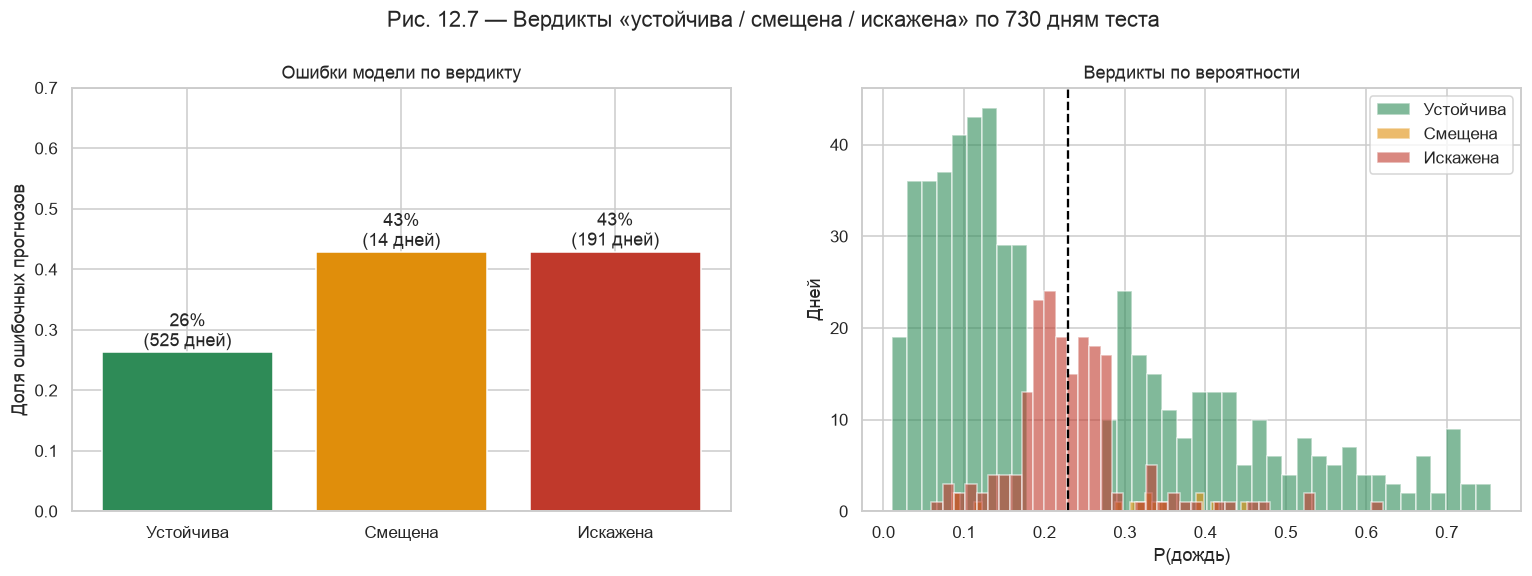

«Смещена» — чаще всего доминирует: {'Давление, гПа': 13, 'Осадки сегодня, мм': 1}


Постеры трёх опорных дней сохранены: figures/poster_*.png


,Дней,Доля ошибок,Средняя P,Доля дней
Вердикт,,,,
Искажена,191,0.429,0.232,0.262
Смещена,14,0.429,0.301,0.019
Устойчива,525,0.263,0.237,0.719


In [10]:
V = []
for i in range(len(test)):
    v, reasons, nums = suggest_verdict(p_te[i], THR, sv[i], LIME[i])
    V.append({"Дата": test.date.iloc[i].date(), "Вердикт": v, "P": p_te[i], "Ошибка": int((p_te[i] >= THR) != y_te[i]),
              "Доля главного": nums["dominance"], "Главный признак": RU[int(np.argmax(np.abs(sv[i])))]})
V = pd.DataFrame(V)
vt = V.groupby("Вердикт").agg(Дней=("Дата", "size"), **{"Доля ошибок": ("Ошибка", "mean"), "Средняя P": ("P", "mean")})
vt["Доля дней"] = vt["Дней"] / len(V)
dom_feat = V[V["Вердикт"] == "Смещена"]["Главный признак"].value_counts().head(3)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
order = [v for v in VERDICTS if v in vt.index]
axes[0].bar(order, vt.loc[order, "Доля ошибок"], color=[VERDICT_COLORS[v] for v in order])
for k, v in enumerate(order):
    axes[0].text(k, vt.loc[v, "Доля ошибок"] + 0.01, f"{vt.loc[v, 'Доля ошибок']:.0%}\n({vt.loc[v, 'Дней']} дней)", ha="center")
axes[0].set(ylabel="Доля ошибочных прогнозов", title="Ошибки модели по вердикту", ylim=(0, 0.7))
for v in order:
    axes[1].hist(V[V["Вердикт"] == v].P, bins=40, alpha=0.6, color=VERDICT_COLORS[v], label=v)
axes[1].axvline(THR, color="black", ls="--"); axes[1].set(xlabel="P(дождь)", ylabel="Дней", title="Вердикты по вероятности"); axes[1].legend()
fig.suptitle("Рис. 12.7 — Вердикты «устойчива / смещена / искажена» по 730 дням теста", y=1.02)
save("fig_12_7_verdicts")
print("«Смещена» — чаще всего доминирует:", dom_feat.to_dict())
for case, i in IDX.items():
    v, reasons, _ = suggest_verdict(p_te[i], THR, sv[i], LIME[i])
    png = make_poster(f"{case}", f"P(дождь) = {p_te[i]:.2f} при пороге {THR:.2f}; факт: {'дождь' if y_te[i] else 'сухо'} · Random Forest",
                      pd.Series(sv[i], index=RU), pd.Series(LIME[i], index=RU), v, reasons,
                      "Рефлексия заполняется студентом на странице приложения «Вердикт и постер».")
    (FIG / f"poster_{CASES[case]}.png").write_bytes(png)
print("Постеры трёх опорных дней сохранены: figures/poster_*.png")
vt.round(3)

**Интерпретация (вердикты).**

- **Вердикт связан с ошибками модели.** Среди дней «Искажена» (191 день, 26 %) модель ошибается в **42.9 %** случаев, среди «Устойчива» (525 дней, 72 %) — в **26.3 %**. То есть вердикт по объяснению — полезный сигнал «проверь вручную», хотя он ничего не знает о факте.
- **«Смещена» встречается редко — 14 дней (2 %),** и почти всегда виновато **давление** (13 из 14). Порог 30 % выбран по распределению: Random Forest распределяет вклад между многими признаками (главный признак — в среднем 22 %), поэтому 40 % из материалов курса у нашей модели не достигается ни разу. Пример постера курса («модель смотрит только на солнце») у нас — «модель смотрит только на барометр»: такие дни особенно уязвимы к сдвигу барометра (ноутбуки 04 и 10).
- **Вердикт ≠ правильность.** Ложная тревога 12.09.2024 получила «Устойчива»: объяснение надёжно, а ошибка — от нехватки информации в данных. Именно это стоит сказать на экзамене рядом с постером.
- Постеры трёх опорных дней сохранены в `figures/poster_*.png`. Постер для любого дня, со своим вердиктом и рефлексией, собирается на странице приложения **«Вердикт и постер»**.

---
# Итог: 12 вопросов — 12 ответов о нашей модели

| № | Метод | Вопрос | Ответ для нашей модели |
|---|---|---|---|
| 1 | SHAP | Что внесло вклад? | осадки сегодня и давление; база 0.243 + вклады = прогноз |
| 2 | LIME | Почему этот случай? | те же главные признаки, правила с порогами; согласие с SHAP 0.92 (медиана) |
| 3 | PDP | Средний эффект? | давление — ступенька у 1012–1015 гПа (−0.17); осадки сегодня — ступенька у 1 мм (+0.12) |
| 4 | ICE | Одинаков ли эффект? | нет: эффект осадков от 0 до +0.27 по дням — сильные взаимодействия |
| 5 | MDI | Что важно глобально? | совпадает с SHAP (ρ 0.95), но завышает непрерывные признаки |
| 6 | Перестановка | Насколько модель зависит? | 9 признаков не нужны на тесте (дублируют другие) |
| 7 | Суррогат | Можно ли простыми правилами? | 8 правил: 84 % совпадений; корень — «был ли дождь сегодня» |
| 8 | Контрфакты | Что изменить для другого решения? | пропуск 10.06.2025 был близок (1.6 ст. откл.); дождливые дни устойчивы (4 признака) |
| 9 | Anchors | Что закрепляет решение? | «осадки сегодня ≥ 0.9 и за 3 дня ≥ 5.3 мм → дождь» (точность 0.93) |
| 10 | Grad-CAM | Куда смотрит CNN? | неприменим: нет изображений и свёрточной сети |
| 11 | IG | Вклад на пути от эталона? | на MLP: давление главное; полнота до 0.007 |
| 12 | DeepLIFT | Отличие от эталона по активациям? | на MLP совпадает с IG (r = 1.00), точная полнота |

**Главный вывод:** методы не конкурируют, а отвечают на разные вопросы. Глобальные (MDI, перестановка, PDP) говорят, что модель в целом опирается на физически правильные признаки. Локальные (SHAP, LIME, IG, DeepLIFT) объясняют конкретный день. Ориентированные на решение (суррогат, контрфакты, Anchors) переводят модель на язык правил и «насколько близко было другое решение». Ни один метод не обнаружил у модели логики, противоречащей метеорологии. Её ошибки — это дни, информации о которых **нет в суточных данных**.